# Experimental waveform energy analysis

For every injection-time column $i$, the denominator comes from **`ref_waveforms[:, i]`**, not a shared static trace, a last-delay trace, or an averaged reference.

$$R_i^{\mathrm{pulse}}=\frac{\Delta t\,\sum_n [E_{\mathrm{mod},i}(t_n)]^2}{\Delta t\,\sum_n [E_{\mathrm{ref},i}(t_n)]^2},\qquad \Delta_i^{\mathrm{pulse}}=100(R_i^{\mathrm{pulse}}-1).$$

$$R_i^{\mathrm{lobe}}=\frac{\int_{z_{-,\mathrm{mod},i}}^{z_{+,\mathrm{mod},i}}E_{\mathrm{mod},i}(t)^2\,dt}{\int_{z_{-,\mathrm{ref},i}}^{z_{+,\mathrm{ref},i}}E_{\mathrm{ref},i}(t)^2\,dt}.$$

Lobe selection uses the same fixed target time and peak sign for every trace, and each trace's own interpolated zero crossings.

**Before running:** keep the four experimental `.txt` files beside this notebook, check `TIME_UNIT`, time alignment, and the selected target lobe. The final sections also load stored scans from `simulate_experimental_setup.ipynb` and overlay the same two analyses. Experimental normalization remains paired by column; each simulation is normalized to its own saved unpumped transmitted trace. Dependencies: NumPy, SciPy, and Matplotlib; no FDTD simulations or custom `lightmatter` imports are needed for this analysis.

## 1. Load the experimental files
The original file names and column order are retained. Rows are waveform time samples; column `i` corresponds to `injection_times[i]` in **both** matrices.

In [1]:
from pathlib import Path
import json
import numpy as np

LIGHTMATTER_ROOT = next(
    (candidate for root in (Path.cwd(), *Path.cwd().parents)
     for candidate in (root, root / "lightmatter")
     if (candidate / "notebooks/project_2/experimental_data_analysis.ipynb").is_file()),
    None,
)
if LIGHTMATTER_ROOT is None:
    raise FileNotFoundError("Run this notebook from within the lightmatter workspace.")
EXPERIMENTAL_DATA_DIR = LIGHTMATTER_ROOT / "notebooks/project_2"
SIMULATION_OUTPUT_ROOT = LIGHTMATTER_ROOT / "output/project2"


In [2]:
time_ax = np.genfromtxt("time_axis.txt",delimiter=",")
ref_waveforms = np.genfromtxt("ref_field.txt",delimiter=",")
modified_waveforms = np.genfromtxt("mod_field.txt",delimiter=",")
injection_times = np.genfromtxt("inj_time.txt",delimiter=",")

In [3]:
ref_waveforms.shape

(80057, 48)

## 2. Analysis functions
These cells make the notebook self-contained. All function-level time arguments are in **seconds**. The experimental and simulation comparisons below call these same functions, including `sum(E**2)*dt` for pulse energy and each trace's own zero crossings for lobe energy.


In [3]:
"""Experimental versions of the two analyses in simulation_setup.ipynb.

Waveforms have shape (number_of_time_samples, number_of_injection_times).
Column i of modified_waveforms is always divided by the energy from column i
of ref_waveforms. All time arguments to these functions are in SECONDS.

Whole-pulse analysis:
sum(E**2) * dt.
Fixed-cycle analysis: signed-peak selection and trapezoidal
integration of E**2 between that waveform's interpolated bounding zeros.

The representative reference_index affects plots ONLY, never normalization.
"""

import warnings

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid, trapezoid
from scipy.signal import find_peaks



def _time_array(t):
    t = np.asarray(t, dtype=float)
    if t.ndim != 1 or t.size < 3 or not np.all(np.isfinite(t)):
        raise ValueError("t must be a finite 1D array with at least three samples.")
    if not np.all(np.diff(t) > 0.0):
        raise ValueError("t must be strictly increasing; check the input time axis.")
    return t


def _uniform_dt(t):
    dt = float(np.mean(np.diff(t)))
    if not np.allclose(np.diff(t), dt, rtol=1e-4, atol=abs(dt) * 1e-9):
        raise ValueError("The FFT filter requires a uniformly sampled time axis.")
    return dt


def _waveform(E, t):
    if np.iscomplexobj(E):
        raise ValueError("Use the real electric-field waveform, not a complex envelope.")
    E = np.asarray(E, dtype=float)
    if E.shape != t.shape or not np.all(np.isfinite(E)):
        raise ValueError("A waveform must be finite and have the same shape as t.")
    return E


def _paired_data(t, ref_waveforms, modified_waveforms, injection_times):
    t = _time_array(t)
    inj = np.asarray(injection_times, dtype=float)
    if inj.ndim != 1 or inj.size == 0 or not np.all(np.isfinite(inj)):
        raise ValueError("injection_times must be a nonempty, finite 1D array.")
    if np.iscomplexobj(ref_waveforms) or np.iscomplexobj(modified_waveforms):
        raise ValueError("The input waveforms must be real electric fields.")
    ref = np.asarray(ref_waveforms, dtype=float)
    mod = np.asarray(modified_waveforms, dtype=float)
    expected = (t.size, inj.size)
    if ref.shape != expected or mod.shape != expected:
        raise ValueError(
            f"Expected both waveform arrays to have shape {expected} "
            f"(time samples, injection times); got {ref.shape} and {mod.shape}."
        )
    if not np.all(np.isfinite(ref)) or not np.all(np.isfinite(mod)):
        raise ValueError("Waveforms contain NaN or infinity; check the loaded text files.")
    return t, ref, mod, inj



In [4]:
# %% Plot helper: the displayed reference is not used as a shared denominator

def _display_scaled(x):
    scale = np.max(np.abs(x))
    return x / scale if scale > 0.0 else np.zeros_like(x)


def _plot_analysis(t, inj, y, reference, *, reference_index, ylabel,
                   title, include_vector_potential=True, target_time_s=None,
                   xlim_fs=None, baseline=None):
    fig, ax = plt.subplots(figsize=(12, 6))
    # Sort only the plotted coordinates, never the paired input arrays.
    order = np.argsort(inj, kind="stable")
    ax.plot(inj[order] * 1e15, y[order], linewidth=2, label=ylabel)
    if baseline is not None:
        ax.axhline(baseline, linewidth=0.8, linestyle=":", alpha=0.6)
    if target_time_s is not None:
        ax.axvline(target_time_s * 1e15, linewidth=1, linestyle="--",
                   label="Fixed target peak time")
    ax.set_xlabel("Injection time (fs)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    if xlim_fs is not None:
        ax.set_xlim(xlim_fs)
    elif inj.size > 1 and np.ptp(inj) > 0:
        span = np.ptp(inj) * 1e15
        ax.set_xlim(np.min(inj) * 1e15 - 0.02 * span,
                    np.max(inj) * 1e15 + 0.02 * span)

    right = ax.twinx()
    label = f"Reference E, column {reference_index} (display-scaled)"
    right.plot(t * 1e15, _display_scaled(reference), linewidth=1,
               linestyle="--", alpha=0.6, label=label)
    if include_vector_potential:
        A = -cumulative_trapezoid(reference, t, initial=0.0)
        right.plot(t * 1e15, _display_scaled(A), linewidth=1,
                   linestyle="-.", alpha=0.6,
                   label=f"Reference A, column {reference_index} (display-scaled)")
    right.set_ylabel("Reference overlays (each scaled to unit maximum magnitude)")
    lines1, labels1 = ax.get_legend_handles_labels()
    lines2, labels2 = right.get_legend_handles_labels()
    ax.legend(lines1 + lines2, labels1 + labels2, fontsize=9)
    fig.tight_layout()
    plt.show()
    return fig




In [5]:
# %% Analysis 1: whole-pulse energy

def complete_integral_analysis(t, ref_waveforms, modified_waveforms,
                               injection_times, *,
                               plot=True,
                               reference_index=0, xlim_fs=None):
    """Compute whole-pulse energies and their per-injection ratios.

    Times are in seconds; waveforms are (Nt, Ninj). The original simulation
    used sum(E**2) * dt, which is preserved for numerator AND denominator.
    Returned arrays retain the original injection-time/column order.
    """
    t, ref, mod, inj = _paired_data(t, ref_waveforms, modified_waveforms, injection_times)
    if not isinstance(reference_index, (int, np.integer)) or not 0 <= reference_index < inj.size:
        raise ValueError("reference_index must select an existing waveform column.")

    dt=_uniform_dt(t)
    energy_reference = np.empty(inj.size)
    energy_modified = np.empty(inj.size)
    reference = None
    # Process one pair at a time, avoiding full (Nt, Ninj) complex FFT arrays.
    for i in range(inj.size):
        energy_reference[i] = np.sum(ref[:,i] ** 2) * dt
        energy_modified[i] = np.sum(mod[:,i] ** 2) * dt
        if i == reference_index:
            reference = ref[:,i]

    bad = (~np.isfinite(energy_reference)) | (energy_reference <= 0.0)
    if np.any(bad):
        raise ValueError(f"Invalid/zero reference energies in columns {np.flatnonzero(bad).tolist()}.")
    if not np.all(np.isfinite(energy_modified)):
        raise ValueError("Nonfinite modified pulse energy; check the input amplitudes.")
    ratio = energy_modified / energy_reference  # elementwise, NOT a scalar reference
    percent_change = (ratio - 1.0) * 100.0
    result = {
        "injection_times_s": inj.copy(),
        "energy_reference": energy_reference,
        "energy_modified": energy_modified,
        "ratio": ratio,
        "percent_change": percent_change,
        "reference_index": reference_index,
        "reference": reference,
        "vector_potential": -cumulative_trapezoid(reference, t, initial=0.0),
        "figures": [],
    }
    if plot:
        result["figures"].append(_plot_analysis(
            t, inj, percent_change, reference,
            reference_index=reference_index,
            ylabel="Change in pulse energy (%)",
            title="Integrated pulse-energy change: per-injection reference normalization",
            xlim_fs=xlim_fs, baseline=0.0,
        ))
    return result




In [6]:
# %% Analysis 2: lobe energy between that waveform's zero crossings

def _signed_peaks(E, peak_type, peak_prominence_fraction):
    if peak_type not in ("positive", "negative"):
        raise ValueError("peak_type must be 'positive' or 'negative'.")
    if not np.isfinite(peak_prominence_fraction) or peak_prominence_fraction < 0:
        raise ValueError("peak_prominence_fraction must be finite and nonnegative.")
    sign = 1.0 if peak_type == "positive" else -1.0
    prominence = (peak_prominence_fraction * np.max(np.abs(E))
                  if peak_prominence_fraction > 0 else None)
    peaks, _ = find_peaks(sign * E, prominence=prominence)
    # Reject, for example, a noise-induced local maximum that is still negative.
    return peaks[sign * E[peaks] > 0.0]


def _zero_crossings_linear(t, E):
    # No dependency on the custom lightmatter package is needed.
    idx = np.flatnonzero(((E[:-1] < 0) & (E[1:] > 0))
                         | ((E[:-1] > 0) & (E[1:] < 0)))
    # Magnitude form of linear interpolation avoids sign ambiguity.
    fraction = np.abs(E[idx]) / (np.abs(E[idx]) + np.abs(E[idx + 1]))
    crossing_times = t[idx] + fraction * (t[idx + 1] - t[idx])
    return np.unique(np.r_[crossing_times, t[E == 0.0]])


def peak_lobe_energy(t, E, t_closest_SI, peak_type="positive", *,
                     peak_prominence_fraction=0.0, max_peak_distance_s=None,
                     return_details=False):
    """Nearest signed peak, own bounding zeros, trapezoidal integral of raw E**2.

    t and t_closest_SI are in seconds, already on the desired experimental time
    coordinate. No simulation propagation-time correction is applied.
    Prominence and distance safeguards are optional; no smoothing is performed.
    """
    t = _time_array(t)
    E = _waveform(E, t)
    if not np.isfinite(t_closest_SI) or not t[0] <= t_closest_SI <= t[-1]:
        raise ValueError("t_closest_SI must be finite and within the sampled time range.")
    if max_peak_distance_s is not None:
        if not np.isfinite(max_peak_distance_s) or max_peak_distance_s < 0:
            raise ValueError("max_peak_distance_s must be finite and nonnegative.")
    peaks = _signed_peaks(E, peak_type, peak_prominence_fraction)
    if peaks.size == 0:
        raise ValueError(f"No eligible {peak_type} peaks were found.")
    peak_id = peaks[np.argmin(np.abs(t[peaks] - t_closest_SI))]
    t_peak = t[peak_id]
    if max_peak_distance_s is not None and abs(t_peak - t_closest_SI) > max_peak_distance_s:
        raise ValueError("Nearest eligible peak lies outside max_peak_distance_s.")

    zeros = _zero_crossings_linear(t, E)
    before, after = zeros[zeros < t_peak], zeros[zeros > t_peak]
    if before.size == 0 or after.size == 0:
        raise ValueError("The selected peak is not bounded by zeros on both sides.")
    t_left, t_right = before[-1], after[0]
    inside = (t > t_left) & (t < t_right)
    t_interval = np.r_[t_left, t[inside], t_right]
    E_interval = np.r_[0.0, E[inside], 0.0]
    energy = float(trapezoid(E_interval ** 2, x=t_interval))
    if not np.isfinite(energy) or energy <= 0.0:
        raise ValueError("The selected lobe has zero or nonfinite energy.")
    details = {
        "energy": energy, "peak_index": int(peak_id), "peak_time_s": float(t_peak),
        "left_zero_s": float(t_left), "right_zero_s": float(t_right),
    }
    return details if return_details else energy


def fixed_cycle(t, ref_waveforms, modified_waveforms, injection_times,
                closest_peak_time_SI, peak_type="positive", *,
                peak_prominence_fraction=0.0, max_peak_distance_s=None,
                on_error="raise", plot=True, reference_index=0, xlim_fs=None):
    """Per-injection lobe energy ratio at a fixed target peak time.

    The same target time and sign select a lobe in each modified/reference trace;
    each selected lobe has its OWN zero-crossing integration boundaries, as in
    the simulation notebook. Normalization uses the corresponding reference
    column, never a last-delay reference or an average reference waveform.

    on_error='raise' identifies the first invalid pair (default).
    on_error='nan' records failed pairs, emits a warning, and leaves their ratios
    as NaN; it never substitutes a different normalization or fills a missing lobe.
    """
    
    t, ref, mod, inj = _paired_data(t, ref_waveforms, modified_waveforms, injection_times)
    if on_error not in ("raise", "nan"):
        raise ValueError("on_error must be 'raise' or 'nan'.")
    if not isinstance(reference_index, (int, np.integer)) or not 0 <= reference_index < inj.size:
        raise ValueError("reference_index must select an existing waveform column.")
    if not np.isfinite(closest_peak_time_SI) or not t[0] <= closest_peak_time_SI <= t[-1]:
        raise ValueError("closest_peak_time_SI must be within the sampled time range.")
    
    # Validate shared selection settings before any per-column error handling.
    _signed_peaks(ref[:, reference_index], peak_type, peak_prominence_fraction)
    if max_peak_distance_s is not None:
        if not np.isfinite(max_peak_distance_s) or max_peak_distance_s < 0:
            raise ValueError("max_peak_distance_s must be finite and nonnegative.")

    fields = ("energy_reference", "energy_modified", "reference_peak_time_s",
              "modified_peak_time_s", "reference_left_zero_s", "reference_right_zero_s",
              "modified_left_zero_s", "modified_right_zero_s")
    result = {name: np.full(inj.size, np.nan) for name in fields}
    errors = [""] * inj.size
    options = dict(peak_type=peak_type, peak_prominence_fraction=peak_prominence_fraction,
                   max_peak_distance_s=max_peak_distance_s, return_details=True)
    for i in range(inj.size):
        try:
            r = peak_lobe_energy(t, ref[:, i], closest_peak_time_SI, **options)
            m = peak_lobe_energy(t, mod[:, i], closest_peak_time_SI, **options)
        except ValueError as exc:
            message = f"Column {i}, injection time {inj[i] * 1e15:g} fs: {exc}"
            if on_error == "raise":
                raise ValueError(message) from exc
            errors[i] = message
            continue
        result["energy_reference"][i] = r["energy"]
        result["energy_modified"][i] = m["energy"]
        for prefix, data in (("reference", r), ("modified", m)):
            result[f"{prefix}_peak_time_s"][i] = data["peak_time_s"]
            result[f"{prefix}_left_zero_s"][i] = data["left_zero_s"]
            result[f"{prefix}_right_zero_s"][i] = data["right_zero_s"]

    result["ratio"] = result["energy_modified"] / result["energy_reference"]
    result["percent_change"] = (result["ratio"] - 1.0) * 100.0
    result["valid"] = np.isfinite(result["ratio"])
    result["errors"] = errors
    result["injection_times_s"] = inj.copy()
    result["target_peak_time_s"] = closest_peak_time_SI
    result["reference_index"] = reference_index
    result["figures"] = []
    if any(errors):
        warnings.warn(f"Lobe selection failed in {sum(bool(e) for e in errors)} pair(s). "
                      "Their results are NaN; inspect result['errors'].", RuntimeWarning,
                      stacklevel=2)
    if plot:
        result["figures"].append(_plot_analysis(
            t, inj, result["ratio"], ref[:, reference_index],
            reference_index=reference_index,
            ylabel="Lobe energy ratio (modified / paired reference)",
            title="Fixed-lobe energy: per-injection reference normalization",
            target_time_s=closest_peak_time_SI, xlim_fs=xlim_fs, baseline=1.0,
        ))
    return result


## 3. Units, time alignment, and lobe selection

Set `TIME_UNIT` explicitly to `"s"`, `"ps"`, or `"fs"`. Leave `INJECTION_TIME_UNIT = None` only when the injection-time file uses the same unit. The configuration deliberately stops if waveform units have not been chosen.

The waveform and injection-time coordinates must share the time origin and sign convention you intend to compare. No FDTD propagation delay is assumed for experimental data. `WAVEFORM_TIME_SHIFT_FS` is **added** to the waveform axis; for example, a known propagation correction would be entered with a negative sign. `INJECTION_TIME_SIGN` is $+1$ by default; change it to $-1$ only if the measured delay convention requires it. The injection shift is added after applying that sign. The supplied notebooks do not establish an experimental alignment correction.

`CLOSEST_PEAK_TIME_FS` is a **fixed time in the aligned waveform coordinate**, not an injection-dependent time. With `None`, the notebook explicitly selects the strongest peak of `PEAK_TYPE` in `REFERENCE_INDEX` as a starting choice and prints its time. Replace it with your desired lobe's peak time after inspecting the preview. The default sign is negative, following the active simulation example; its numerical simulation target time is not imposed on experimental data.

The optional prominence and maximum-distance settings help reject noise extrema or distant lobes. They do not filter, smooth, or baseline-subtract the waveform. The integration amplitudes remain untouched.

In [7]:
# REQUIRED: choose the actual units used in your files. No units are guessed.
TIME_UNIT = "fs"                  # "s", "ps", or "fs"
INJECTION_TIME_UNIT = "fs"        # None means the same units as TIME_UNIT

WAVEFORM_TIME_SHIFT_FS = 0.0       # Added after converting time_ax to seconds
INJECTION_TIME_SIGN = 1.0         # Use -1.0 only for a reversed delay convention
INJECTION_TIME_SHIFT_FS = 0.0

REFERENCE_INDEX = 0              # Display/initial lobe choice ONLY; not normalization
PEAK_TYPE = "positive"            # "positive" or "negative"
# PEAK_TYPE = "negative"
CLOSEST_PEAK_TIME_FS = 33.5        # None: choose strongest PEAK_TYPE in displayed reference
PEAK_PROMINENCE_FRACTION = 0.0     # Optional fraction of each trace's max |E|; 0 disables
MAX_PEAK_DISTANCE_FS = None       # Optional maximum distance from the fixed target time

XLIM_FS = None                   # e.g. (-30.0, 30.0), in aligned injection-time coordinates
PREVIEW_HALF_WIDTH_FS = 15.0
ON_LOBE_ERROR = "raise"           # Or "nan": warns and records failed pairs, without substitution

In [8]:
unit_to_s = {"s": 1.0, "ps": 1e-12, "fs": 1e-15}
if TIME_UNIT not in unit_to_s:
    raise ValueError('Set TIME_UNIT to "s", "ps", or "fs" in the configuration cell.')
inj_unit = TIME_UNIT if INJECTION_TIME_UNIT is None else INJECTION_TIME_UNIT
if inj_unit not in unit_to_s:
    raise ValueError('Set INJECTION_TIME_UNIT to "s", "ps", "fs", or None.')
if INJECTION_TIME_SIGN not in (-1.0, 1.0):
    raise ValueError("INJECTION_TIME_SIGN must be +1 or -1.")

# Original arrays are retained; these are new, aligned SI time coordinates.
t_SI = np.asarray(time_ax, dtype=float) * unit_to_s[TIME_UNIT] + WAVEFORM_TIME_SHIFT_FS * 1e-15
injection_times_SI = (
    INJECTION_TIME_SIGN * np.asarray(injection_times, dtype=float) * unit_to_s[inj_unit]
    + INJECTION_TIME_SHIFT_FS * 1e-15
)
_, _, _, _ = _paired_data(t_SI, ref_waveforms, modified_waveforms, injection_times_SI)
if not isinstance(REFERENCE_INDEX, (int, np.integer)) or not 0 <= REFERENCE_INDEX < injection_times_SI.size:
    raise ValueError("REFERENCE_INDEX must select an existing waveform column.")
max_peak_distance_s = None if MAX_PEAK_DISTANCE_FS is None else MAX_PEAK_DISTANCE_FS * 1e-15
print(f"Aligned waveform range: {t_SI[0] * 1e15:g} to {t_SI[-1] * 1e15:g} fs")
print(f"Sampling interval: {np.mean(np.diff(t_SI)) * 1e15:g} fs")
print(f"Aligned injection range: {injection_times_SI.min() * 1e15:g} to {injection_times_SI.max() * 1e15:g} fs")

Aligned waveform range: 0 to 80.056 fs
Sampling interval: 0.001 fs
Aligned injection range: -239.422 to 115.454 fs


## 4. Whole-pulse analysis
The energy calculation retains the simulation convention `sum(E**2) * dt`. The optional second plot shows the **same  energy result**, with a reference field overlaid

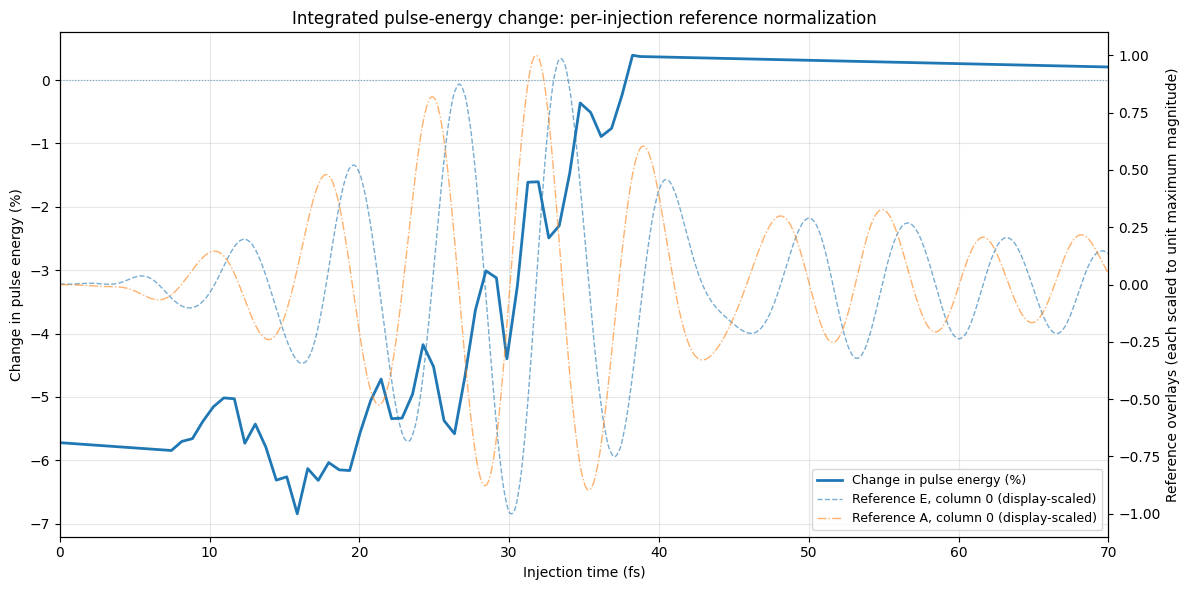

In [9]:
integrated = complete_integral_analysis(
    t_SI, ref_waveforms, modified_waveforms, injection_times_SI,
    reference_index=REFERENCE_INDEX,
    xlim_fs=(0,70)
)

arr = integrated["ratio"]
energy_reference = integrated["energy_reference"]   # one denominator PER injection time
energy_modified = integrated["energy_modified"]
energy_change_percent = integrated["percent_change"]

## 5. Preview the chosen lobe
The preview uses one representative pair only. All pairs are still analyzed and normalized separately. Inspect the sign, target peak, and zero crossings before interpreting the lobe scan. No automatic rephasing or peak-time drift correction is applied.

Strongest eligible reference-peak times (fs):
[ 5.455 12.33  19.626 26.678 33.43  40.469 50.032 56.63  63.214 69.593]
Fixed positive target time for ALL pairs: 33.500000 fs


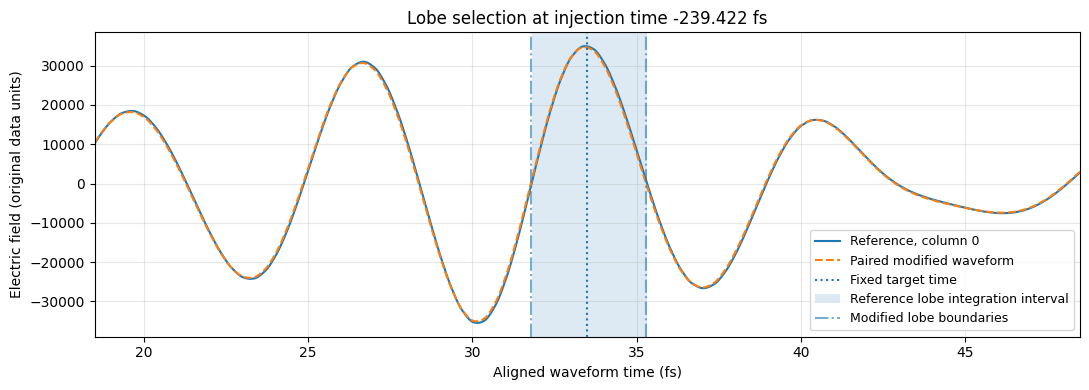

In [10]:
reference_preview = ref_waveforms[:, REFERENCE_INDEX]
candidate_peaks = _signed_peaks(reference_preview, PEAK_TYPE, PEAK_PROMINENCE_FRACTION)
if candidate_peaks.size == 0:
    raise ValueError(f"No eligible {PEAK_TYPE} peaks in the selected reference.")

# Show the ten strongest eligible reference peaks in chronological order.
strongest = candidate_peaks[np.argsort(np.abs(reference_preview[candidate_peaks]))[-10:]]
strongest = strongest[np.argsort(t_SI[strongest])]
print("Strongest eligible reference-peak times (fs):")
print(np.round(t_SI[strongest] * 1e15, 6))

if CLOSEST_PEAK_TIME_FS is None:
    chosen_peak = candidate_peaks[np.argmax(np.abs(reference_preview[candidate_peaks]))]
    closest_peak_time_SI = float(t_SI[chosen_peak])
    print("Automatic starting choice: strongest eligible peak in the displayed reference.")
else:
    closest_peak_time_SI = float(CLOSEST_PEAK_TIME_FS) * 1e-15
print(f"Fixed {PEAK_TYPE} target time for ALL pairs: {closest_peak_time_SI * 1e15:.6f} fs")

preview_options = dict(
    peak_type=PEAK_TYPE,
    peak_prominence_fraction=PEAK_PROMINENCE_FRACTION,
    max_peak_distance_s=max_peak_distance_s,
    return_details=True,
)
# Compute the reference selection strictly; diagnose the modified selection too.
preview_ref = peak_lobe_energy(t_SI, reference_preview, closest_peak_time_SI, **preview_options)
try:
    preview_mod = peak_lobe_energy(t_SI, modified_waveforms[:, REFERENCE_INDEX],
                                  closest_peak_time_SI, **preview_options)
except ValueError as exc:
    preview_mod = None
    print("Modified preview lobe could not be selected:", exc)

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(t_SI * 1e15, reference_preview, label=f"Reference, column {REFERENCE_INDEX}")
ax.plot(t_SI * 1e15, modified_waveforms[:, REFERENCE_INDEX], linestyle="--", label="Paired modified waveform")
ax.axvline(closest_peak_time_SI * 1e15, linestyle=":", label="Fixed target time")
ax.axvspan(preview_ref["left_zero_s"] * 1e15, preview_ref["right_zero_s"] * 1e15,
           alpha=0.15, label="Reference lobe integration interval")
if preview_mod is not None:
    ax.axvline(preview_mod["left_zero_s"] * 1e15, linestyle="-.", alpha=0.6,
               label="Modified lobe boundaries")
    ax.axvline(preview_mod["right_zero_s"] * 1e15, linestyle="-.", alpha=0.6)
ax.set_xlim(closest_peak_time_SI * 1e15 - PREVIEW_HALF_WIDTH_FS,
            closest_peak_time_SI * 1e15 + PREVIEW_HALF_WIDTH_FS)
ax.set_xlabel("Aligned waveform time (fs)")
ax.set_ylabel("Electric field (original data units)")
ax.set_title(f"Lobe selection at injection time {injection_times_SI[REFERENCE_INDEX] * 1e15:g} fs")
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()

## 6. Fixed-cycle analysis
As in the simulation code, this is the single signed **lobe** between adjacent zero crossings, not a full positive-plus-negative optical cycle. The reference and modified lobes are selected independently near the same fixed target; the reference interval is not imposed on the modified trace.

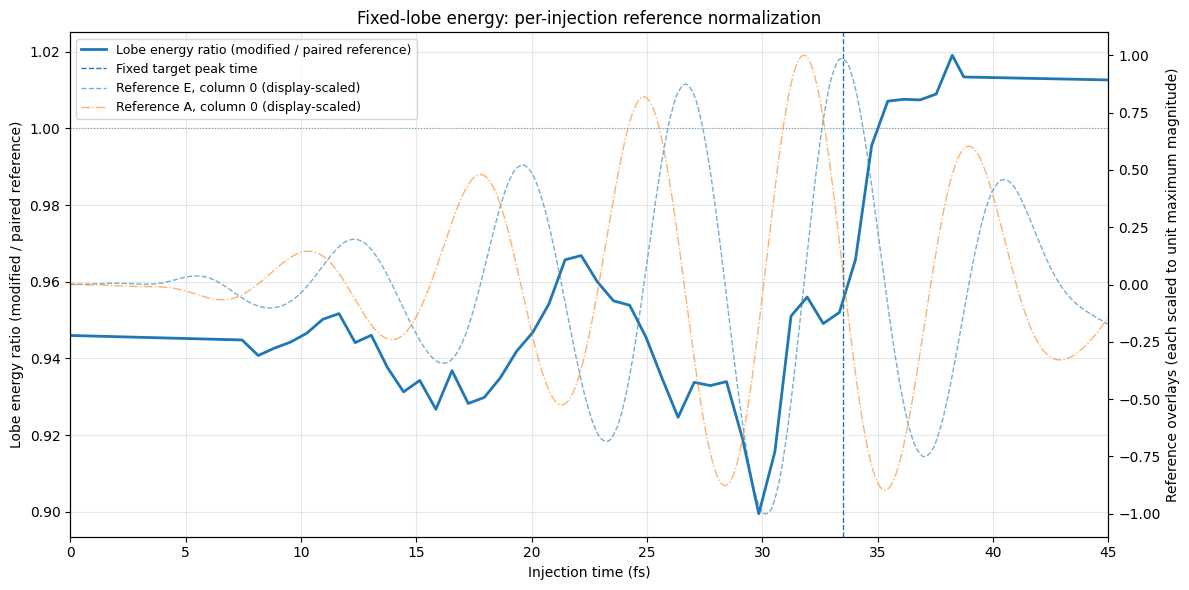

Valid lobe pairs: 48 / 48


In [11]:
lobe = fixed_cycle(
    t_SI, ref_waveforms, modified_waveforms, injection_times_SI,
    closest_peak_time_SI=closest_peak_time_SI,
    peak_type=PEAK_TYPE,
    peak_prominence_fraction=PEAK_PROMINENCE_FRACTION,
    max_peak_distance_s=max_peak_distance_s,
    on_error=ON_LOBE_ERROR,
    reference_index=REFERENCE_INDEX,
    xlim_fs=(0,45),
)

arr_lobe = lobe["ratio"]
lobe_energy_reference = lobe["energy_reference"]   # a separate lobe denominator PER injection time
lobe_energy_modified = lobe["energy_modified"]
lobe_change_percent = lobe["percent_change"]
print(f"Valid lobe pairs: {np.count_nonzero(lobe['valid'])} / {injection_times_SI.size}")
for error in lobe["errors"]:
    if error:
        print(error)

### Check for lobe switching
A sudden change in selected peak time can indicate that the nearest-peak rule has selected a different cycle. This diagnostic exposes the choices without silently rematching them. For noisy data, inspect the raw traces and adjust the target or optional prominence/distance constraints rather than interpreting a failed selection as an energy change.

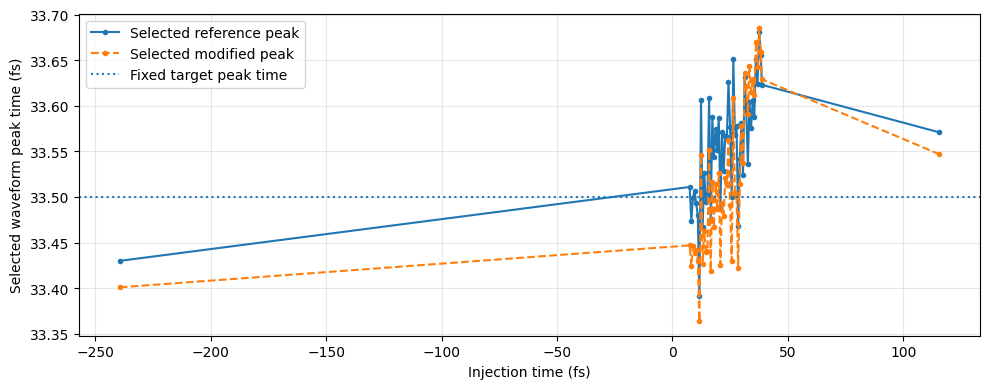

In [12]:
order = np.argsort(injection_times_SI, kind="stable")
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(injection_times_SI[order] * 1e15, lobe["reference_peak_time_s"][order] * 1e15,
        marker=".", label="Selected reference peak")
ax.plot(injection_times_SI[order] * 1e15, lobe["modified_peak_time_s"][order] * 1e15,
        marker=".", linestyle="--", label="Selected modified peak")
ax.axhline(closest_peak_time_SI * 1e15, linestyle=":", label="Fixed target peak time")
ax.set_xlabel("Injection time (fs)")
ax.set_ylabel("Selected waveform peak time (fs)")
ax.grid(True, alpha=0.3)
ax.legend()
fig.tight_layout()
plt.show()

## 7. Results and optional export
All arrays retain the original file column order, even when the plots sort the injection-time axis. The field and vector-potential overlays are each scaled to unit maximum magnitude **for display only**. Their scales, the displayed reference index, and the automatic starting lobe choice do not replace the per-pair energy denominators. Raw integral units are `(field units)^2 s`; ratios and percentage changes are dimensionless.

In [13]:
# Columns below retain the original experimental column order.
results_table = np.column_stack([
    injection_times_SI * 1e15,
    energy_reference, energy_modified, arr, energy_change_percent,
    lobe_energy_reference, lobe_energy_modified, arr_lobe, lobe_change_percent,
    lobe["reference_peak_time_s"] * 1e15,
    lobe["modified_peak_time_s"] * 1e15,
    lobe["reference_left_zero_s"] * 1e15,
    lobe["reference_right_zero_s"] * 1e15,
    lobe["modified_left_zero_s"] * 1e15,
    lobe["modified_right_zero_s"] * 1e15,
    lobe["valid"].astype(int),
])
results_header = (
    "injection_time_fs,pulse_energy_reference,pulse_energy_modified,pulse_ratio,pulse_change_percent,"
    "lobe_energy_reference,lobe_energy_modified,lobe_ratio,lobe_change_percent,"
    "reference_peak_time_fs,modified_peak_time_fs,reference_left_zero_fs,reference_right_zero_fs,"
    "modified_left_zero_fs,modified_right_zero_fs,lobe_valid"
)

# Uncomment to save the analysis on your machine.
# np.savetxt("experimental_energy_analysis.csv", results_table,
#            delimiter=",", header=results_header, comments="")

## 8. Stored simulations and comparison conventions

The following cells discover `probe_pump_sqrt_E*` folders written by `simulate_experimental_setup.ipynb`. New folder names use `probe_pump_sqrt_E<p>_3fs_1p5eV_gamma_D0_<value>_ps-1_del_omega_D_<value>_rad-ps-1_<interpolation>`, with the pump-field exponent in the name and both material-parameter values formatted to four decimal places. The discovery pattern also accepts legacy names; material parameters are read from the saved metadata, not parsed from folder names. They read the **manifest**, `scan_configuration.json`, and each run's `data.npz`/`info.json`; no material cache is loaded and no simulation is rerun. By default incomplete scans are reported and skipped. `ALLOW_PARTIAL_SCANS=True` includes only manifest-confirmed completed runs, marks the dataset partial, and leaves gaps instead of filling missing delays.

**Injection axis:** the experimental `inj_time.txt` contains **pump arrival times on the experimental waveform axis**. The saved simulation delay is $\Delta=t_{\rm probe,peak}-t_{\rm pump,peak}$, so
$$
 t_{\rm pump,experiment}=t_{\rm probe,peak,experiment}-\Delta.
$$
For corrected-source scans, the incident `abs(E)` peak comes from the corrected field on its documented time axis, after checking the correction metadata, file hashes, and the saved source time grid and amplitude. There is no second baseline subtraction. The correction has already compensated the group transit; neither the propagation time nor the transmitted-waveform alignment is added to this injection coordinate. Legacy scans instead use the baseline-corrected raw reference column that drove them, validated against their saved source. The measured transmitted reference remains the basis for output-waveform alignment and experimental energy normalization. Existing `INJECTION_TIME_SIGN`/`INJECTION_TIME_SHIFT_FS` are then applied to the model's injection coordinates as well. `SIMULATION_INJECTION_OFFSET_FS` is an optional additional known timing calibration, with zero as the default. There is no fitted delay offset or amplitude scaling of the analysis curves.

**Waveform/lobe axis:** this is separate from the injection-delay conversion. One time translation aligns each **unpumped transmitted reference** with its experimental source-reference column, by maximizing positive waveform cross-correlation. This avoids matching opposite-polarity largest peaks. That same translation is applied to **every modified trace**, preserving genuine delay-dependent shifts and lobe changes. Manual shifts can override the reference alignment. The preview below exposes the aligned references and selected lobe; inspect it if dispersion makes the correspondence ambiguous.

**Energy window and normalization:** by default simulated traces are clipped to the experimental time-record window after this common alignment, without resampling their native FDTD time grid. Both numerator and denominator use the same window and `sum(E**2)*dt`. This avoids counting simulation echoes outside the measured record. Full-record simulated pulse ratios are retained separately for diagnostics. Experimental results still use their paired reference columns; simulations use their saved unpumped reference. The same fixed signed-lobe target, prominence/distance settings, and own-zero-crossing integration are used for both. Only dimensionless ratios/percentage changes are compared across different field-amplitude units.

In [ ]:
# Simulation comparison settings
SIMULATION_DIRECTORIES = None     # None discovers all matching folders; or list folder names/Paths
SIMULATION_GLOB = "probe_pump_sqrt_E*"
ALLOW_PARTIAL_SCANS = False
SIMULATION_ENERGY_WINDOW = "experimental"  # or "full_record" for the complete saved FDTD record
SIMULATION_INJECTION_OFFSET_FS = 0.0       # added to the plotted injection coordinate
SIMULATION_WAVEFORM_SHIFTS_FS = {}         # {absolute_folder_path or folder_name: time_shift_fs}
SIMULATION_LABELS = {}                    # {absolute_folder_path or folder_name: display_label}
SIMULATION_DATASET_NAMES = {}             # {absolute_folder_path: unique_export_name}; useful for sweep subfolders
COMPARISON_XLIM_FS = XLIM_FS if XLIM_FS is not None else (0.0, 70.0)
SAVE_COMPARISON = True
COMPARISON_OUTPUT_DIR = SIMULATION_OUTPUT_ROOT / "experimental_simulation_comparison"

if SIMULATION_ENERGY_WINDOW not in ("experimental", "full_record"):
    raise ValueError("SIMULATION_ENERGY_WINDOW must be 'experimental' or 'full_record'.")
if not np.isfinite(SIMULATION_INJECTION_OFFSET_FS):
    raise ValueError("SIMULATION_INJECTION_OFFSET_FS must be finite.")

In [ ]:
# Stored-output loading and reference-only alignment
from scipy.signal import correlate, correlation_lags


def _read_json(path):
    with Path(path).open() as stream:
        return json.load(stream)


def _load_simulation_trace(folder):
    folder = Path(folder)
    info = _read_json(folder / "info.json")
    with np.load(folder / "data.npz", allow_pickle=False) as archive:
        time = _time_array(archive["t_ps"] * 1e-12)
        field = _waveform(archive["E_t"], time)
    params = info["fdtd_params"]
    expected = np.arange(params["Nt"])*params["dt"]*1e-12
    if time.shape != expected.shape or not np.allclose(time, expected, rtol=1e-10, atol=1e-23):
        raise ValueError(f"Saved time axis disagrees with metadata: {folder}")
    _uniform_dt(time)
    return time, field, info


def _simulation_reference_shift(sim_time, sim_field, exp_time, exp_field):
    """One constant offset, from positive reference correlation only; seconds."""
    dt = max(_uniform_dt(sim_time), _uniform_dt(exp_time))
    grid_sim = sim_time[0] + np.arange(int(np.floor((sim_time[-1]-sim_time[0])/dt))+1)*dt
    grid_exp = exp_time[0] + np.arange(int(np.floor((exp_time[-1]-exp_time[0])/dt))+1)*dt
    sim = np.interp(grid_sim, sim_time, sim_field)
    exp = np.interp(grid_exp, exp_time, exp_field)
    norm = np.linalg.norm(sim)*np.linalg.norm(exp)
    if norm <= 0:
        raise ValueError("Cannot align a zero-energy reference waveform.")
    correlation = correlate(sim, exp, mode="full", method="fft")
    lags = correlation_lags(sim.size, exp.size, mode="full")
    peak = int(np.argmax(correlation))  # positive correlation; never flip field polarity
    correction = 0.0
    if 0 < peak < correlation.size-1:
        left, center, right = correlation[peak-1:peak+2]
        curvature = left - 2*center + right
        if curvature < 0:
            correction = float(np.clip(0.5*(left-right)/curvature, -0.5, 0.5))
    shift = exp_time[0]-sim_time[0]-(lags[peak]+correction)*dt
    return float(shift), float(correlation[peak]/norm)


def _simulation_source_peak(root, config):
    """Validate the saved incident source and return its peak on its original clock."""
    column = config["experimental_trace_index"]
    if isinstance(column, bool) or not isinstance(column, int) or not 0 <= column < ref_waveforms.shape[1]:
        raise ValueError(f"Invalid source-reference column in {root}")
    is_corrected = ("probe_source_provenance" in config
                    or "probe_source_correction_metadata" in config)
    if is_corrected:
        import hashlib

        provenance = config.get("probe_source_provenance")
        metadata = config.get("probe_source_correction_metadata")
        if not isinstance(provenance, dict) or not isinstance(metadata, dict):
            raise ValueError(f"Corrected source requires both provenance and correction metadata: {root}")
        if (provenance.get("reference_trace_index") != column
                or metadata.get("reference_trace_index") != column):
            raise ValueError(f"Corrected source trace index disagrees with its provenance: {root}")
        if metadata.get("time_units") != "fs":
            raise ValueError(f"Corrected source metadata must specify a time axis in fs: {root}")
        if config.get("probe_source_baseline_subtracted_in_notebook") is not False:
            raise ValueError(f"Corrected source must not receive a second baseline subtraction: {root}")

        def checked_source_file(filename, expected_hash):
            path = EXPERIMENTAL_DATA_DIR / filename
            with path.open("rb") as stream:
                digest = hashlib.sha256()
                for chunk in iter(lambda: stream.read(1024 * 1024), b""):
                    digest.update(chunk)
            if digest.hexdigest() != expected_hash:
                raise ValueError(f"Corrected source provenance hash differs for {path}")
            return path

        field_path = checked_source_file(provenance["field_filename"], provenance["corrected_field_sha256"])
        time_path = checked_source_file(provenance["time_filename"], provenance["corrected_time_sha256"])
        metadata_path = checked_source_file(provenance["metadata_filename"], provenance["metadata_sha256"])
        if _read_json(metadata_path) != metadata:
            raise ValueError(f"Current and saved correction metadata differ for {root}")
        for key in ("corrected_field_sha256", "corrected_time_sha256"):
            if metadata.get(key) != provenance[key]:
                raise ValueError(f"Corrected source metadata and provenance disagree for {key}: {root}")
        checked_source_file("ref_field.txt", metadata.get("input_field_sha256"))
        checked_source_file("time_axis.txt", metadata.get("input_time_sha256"))
        source_clock_s = _time_array(np.loadtxt(time_path, delimiter=",") * 1e-15)
        incident = _waveform(np.loadtxt(field_path, delimiter=","), source_clock_s)
        peak = float(np.max(np.abs(incident)))
        E0 = float(config["probe_source_peak_E0"])
        if peak <= 0 or not np.isfinite(E0) or E0 <= 0:
            raise ValueError(f"Corrected source and its configured amplitude must be nonzero and finite: {root}")
        # Match the producer: correction already removed the experimental baseline.
        expected_source = incident * (E0 / peak)
    else:
        # Historical scans injected the baseline-corrected measured reference.
        trace = ref_waveforms[:, column]
        n_edge = max(1, int(0.05 * trace.size))
        incident = trace - np.mean(np.r_[trace[:n_edge], trace[-n_edge:]])
        if not np.any(incident):
            raise ValueError("The simulation's experimental source reference is zero.")
        source_clock_s = _time_array(np.asarray(time_ax) * unit_to_s[TIME_UNIT])
        expected_source = _display_scaled(incident)

    with np.load(root / config["shared_axes"], allow_pickle=False) as archive:
        source_time = _time_array(archive["probe_source_t_rel_ps"] * 1e-12)
        source_field = _waveform(archive["probe_source_E"], source_time)
    saved_source = source_field if is_corrected else _display_scaled(source_field)
    if (source_time.shape != source_clock_s.shape
            or not np.allclose(source_time, source_clock_s-source_clock_s[0], rtol=1e-9, atol=1e-20)
            or not np.allclose(saved_source, expected_source, rtol=1e-6,
                               atol=1e-8 * E0 if is_corrected else 1e-8)):
        raise ValueError(f"Saved source and current incident reference differ for {root.name}; check file versions, amplitude, and units.")
    # The correction's documented clock already compensates the group transit.
    # Do not add a propagation time or use the transmitted-reference alignment here.
    return column, float(source_clock_s[int(np.argmax(np.abs(incident)))] * 1e15)


def _available_simulation_scans():
    if SIMULATION_DIRECTORIES is None:
        roots = sorted(p for p in SIMULATION_OUTPUT_ROOT.glob(SIMULATION_GLOB) if p.is_dir())
    else:
        roots = [Path(p) if Path(p).is_absolute() else SIMULATION_OUTPUT_ROOT / p
                 for p in SIMULATION_DIRECTORIES]
    scans, skipped = [], []
    for root in roots:
        manifest = _read_json(root / "scan_manifest.json")
        config = _read_json(root / "scan_configuration.json")
        rows = manifest.get("runs", [])
        completed = set(manifest.get("completed_indices", []))
        planned = [row["index"] for row in rows]
        if len(set(planned)) != len(planned) or not completed.issubset(set(planned)):
            raise ValueError(f"Inconsistent manifest run indices: {root}")
        if manifest.get("complete", False) and completed != set(planned):
            raise ValueError(f"Scan claims completion but manifest entries are incomplete: {root}")
        partial = not manifest.get("complete", False)
        if partial and not ALLOW_PARTIAL_SCANS:
            skipped.append(f"{root.name}: incomplete ({len(completed)}/{len(rows)} runs)")
            continue
        selected = [(position, row) for position, row in enumerate(rows) if row["index"] in completed]
        if not selected:
            skipped.append(f"{root.name}: no completed runs")
            continue
        delays = np.array([row["delay_fs"] for _, row in selected], dtype=float)
        if not np.all(np.isfinite(delays)) or np.unique(delays).size != delays.size:
            raise ValueError(f"Invalid/duplicate manifest delays: {root}")
        if config.get("delay_definition") != "probe incident abs(E) peak minus pump incident abs(E) peak at the sample front; positive=pump first":
            raise ValueError(f"Unrecognized delay convention: {root}; provide an explicit conversion.")
        for _, row in selected:
            folder = root / row["folder"]
            if not (folder / "data.npz").is_file() or not (folder / "info.json").is_file():
                raise FileNotFoundError(f"Manifest-confirmed run is missing saved files: {folder}")
        scans.append((root, config, manifest, selected, partial))
    return scans, skipped

## 9. Apply the existing analyses to each stored simulation

Every selected run is analyzed with `complete_integral_analysis` and `fixed_cycle` from the experimental sections above. The loader checks saved time axes, run delays, material parameters, and the incident source file against the scan configuration. It streams one run at a time. A different lobe or a failed selection is retained in the diagnostics rather than repaired by shifting the modified trace.

In [ ]:
# Analyze completed scans using the existing functions without rerunning FDTD.
available_scans, skipped_simulation_scans = _available_simulation_scans()
for message in skipped_simulation_scans:
    print("Skipped:", message)
if not available_scans:
    raise FileNotFoundError("No usable simulation scans found. Check SIMULATION_DIRECTORIES or explicitly enable ALLOW_PARTIAL_SCANS.")
simulated_analyses = []
comparison_dataset_names = [SIMULATION_DATASET_NAMES.get(str(root.resolve()), root.name)
                            for root, *_ in available_scans]
if (len(set(comparison_dataset_names)) != len(comparison_dataset_names)
        or any(not name or Path(name).name != name or name in (".", "..") for name in comparison_dataset_names)):
    raise ValueError("Comparison datasets need distinct safe export names; set SIMULATION_DATASET_NAMES by absolute scan path.")
for root, config, manifest, rows, partial in available_scans:
    sim_time, sim_reference, ref_info = _load_simulation_trace(root / "unpumped_reference")
    if ref_info.get("material_state") != "unpumped":
        raise ValueError(f"Reference is not unpumped: {root}")
    if ref_info["fdtd_params"] != config["fdtd_params"]:
        raise ValueError(f"Reference and scan geometry differ: {root}")
    if ("pump_field_exponent" in config
            and ref_info.get("pump_field_exponent") != config["pump_field_exponent"]):
        raise ValueError(f"Reference and scan pump-field exponents differ: {root}")
    source_column, source_peak_raw_fs = _simulation_source_peak(root, config)
    experimental_reference = ref_waveforms[:, source_column]
    automatic_shift, alignment_score = _simulation_reference_shift(
        sim_time, sim_reference, t_SI, experimental_reference,
    )
    manual_shift = SIMULATION_WAVEFORM_SHIFTS_FS.get(str(root.resolve()), SIMULATION_WAVEFORM_SHIFTS_FS.get(root.name))
    waveform_shift_s = automatic_shift if manual_shift is None else float(manual_shift)*1e-15
    if not np.isfinite(waveform_shift_s):
        raise ValueError(f"Nonfinite waveform time shift: {root}")
    aligned_time = sim_time + waveform_shift_s
    if SIMULATION_ENERGY_WINDOW == "experimental":
        if aligned_time[0] > t_SI[0] or aligned_time[-1] < t_SI[-1]:
            raise ValueError(f"Simulation does not cover the aligned experimental record: {root}")
        window = (aligned_time >= t_SI[0]) & (aligned_time <= t_SI[-1])
    else:
        window = np.ones(sim_time.size, dtype=bool)
    comparison_time = _time_array(aligned_time[window])
    comparison_reference = sim_reference[window]
    if not comparison_time[0] <= closest_peak_time_SI <= comparison_time[-1]:
        raise ValueError("The fixed experimental lobe target is outside the aligned simulation window.")
    reference_lobe = peak_lobe_energy(
        comparison_time, comparison_reference, closest_peak_time_SI, **preview_options,
    )
    delay_fs = np.array([row["delay_fs"] for _, row in rows], dtype=float)
    # Confirmed experimental convention: pump arrival time in the raw waveform clock.
    plotted_injection_fs = (INJECTION_TIME_SIGN*(source_peak_raw_fs-delay_fs)
                            + INJECTION_TIME_SHIFT_FS + SIMULATION_INJECTION_OFFSET_FS)
    count = len(rows)
    fields = ("pulse_ratio", "pulse_change_percent", "pulse_energy_reference", "pulse_energy_modified",
              "full_record_pulse_ratio", "lobe_ratio", "lobe_change_percent",
              "lobe_energy_reference", "lobe_energy_modified", "reference_peak_time_s",
              "modified_peak_time_s", "reference_left_zero_s", "reference_right_zero_s",
              "modified_left_zero_s", "modified_right_zero_s", "tail_fraction")
    result = {key: np.full(count, np.nan) for key in fields}
    result["lobe_valid"] = np.zeros(count, dtype=bool)
    result["lobe_errors"] = [""]*count
    full_reference_energy = float(np.sum(sim_reference**2)*_uniform_dt(sim_time))
    if full_reference_energy <= 0:
        raise ValueError(f"Zero unpumped reference energy: {root}")
    for j, (_, row) in enumerate(rows):
        run_time, run_field, info = _load_simulation_trace(root / row["folder"])
        if (info.get("material_state") != "pump_driven"
                or not np.isclose(info["delay_fs"], row["delay_fs"], rtol=0, atol=1e-9)
                or info["fdtd_params"] != ref_info["fdtd_params"]
                or info["pulse_params"] != ref_info["pulse_params"]
                or not np.array_equal(run_time, sim_time)):
            raise ValueError(f"Run/reference/manifest mismatch: {root / row['folder']}")
        if ("pump_field_exponent" in config
                and info.get("pump_field_exponent") != config["pump_field_exponent"]):
            raise ValueError(f"Run and scan pump-field exponents differ: {root / row['folder']}")
        for key in ("gamma_D_per_ps", "del_omega_D_rad_per_ps", "omega_D0_rad_per_ps"):
            if not np.isclose(info[key], config[key], rtol=1e-12, atol=0):
                raise ValueError(f"Material metadata mismatch ({key}): {root / row['folder']}")
        pair_ref = comparison_reference[:, None]
        pair_mod = run_field[window, None]
        coordinate_s = plotted_injection_fs[j:j+1]*1e-15
        pulse_result = complete_integral_analysis(
            comparison_time, pair_ref, pair_mod, coordinate_s, plot=False,
        )
        lobe_result = fixed_cycle(
            comparison_time, pair_ref, pair_mod, coordinate_s, closest_peak_time_SI,
            peak_type=PEAK_TYPE, peak_prominence_fraction=PEAK_PROMINENCE_FRACTION,
            max_peak_distance_s=max_peak_distance_s, on_error=ON_LOBE_ERROR, plot=False,
        )
        for prefix, analysis in (("pulse", pulse_result), ("lobe", lobe_result)):
            for key in ("ratio", "percent_change", "energy_reference", "energy_modified"):
                target = f"{prefix}_change_percent" if key == "percent_change" else f"{prefix}_{key}"
                result[target][j] = analysis[key][0]
        for key in ("reference_peak_time_s", "modified_peak_time_s", "reference_left_zero_s",
                    "reference_right_zero_s", "modified_left_zero_s", "modified_right_zero_s"):
            result[key][j] = lobe_result[key][0]
        result["lobe_valid"][j] = lobe_result["valid"][0]
        result["lobe_errors"][j] = lobe_result["errors"][0]
        result["full_record_pulse_ratio"][j] = np.sum(run_field**2)*_uniform_dt(run_time)/full_reference_energy
        result["tail_fraction"][j] = info.get("last_window_transmitted_energy_fraction", np.nan)
    label = SIMULATION_LABELS.get(str(root.resolve()), SIMULATION_LABELS.get(root.name, (
        f"Simulation: gamma_D={config['gamma_D_per_ps']:.4g} /ps, "
        f"delta omega_D={config['del_omega_D_rad_per_ps']:.4g} rad/ps"
    )))
    if partial:
        label += f" [partial: {count}/{len(manifest['runs'])}]"
    result.update(
        name=SIMULATION_DATASET_NAMES.get(str(root.resolve()), root.name), folder=str(root), label=label, partial=partial,
        pump_field_exponent=config.get("pump_field_exponent"),
        pump_common_envelope_phase_rad=config.get("pump_common_envelope_phase_rad"),
        pump_common_envelope_phase_label=config.get("pump_common_envelope_phase_label"),
        manifest_positions=np.array([position for position, _ in rows]),
        manifest_indices=np.array([row["index"] for _, row in rows]),
        run_folders=[row["folder"] for _, row in rows],
        delay_fs=delay_fs, injection_time_fs=plotted_injection_fs,
        waveform_shift_fs=waveform_shift_s*1e15, automatic_waveform_shift_fs=automatic_shift*1e15,
        alignment_score=alignment_score, source_reference_column=source_column,
        source_incident_peak_raw_fs=source_peak_raw_fs,
        reference_time_s=comparison_time, reference_field=comparison_reference,
        reference_lobe=reference_lobe, simulation_configuration=config,
        comparison_window_s=[float(comparison_time[0]), float(comparison_time[-1])],
    )
    simulated_analyses.append(result)
    print(f"{root.name}: {count} runs, waveform shift={waveform_shift_s*1e15:+.4f} fs, reference correlation={alignment_score:.4f}")
    print(f"  Incident probe peak={source_peak_raw_fs:.6f} fs; valid lobes={result['lobe_valid'].sum()}/{count}")
    print(f"  Comparison window={comparison_time[0]*1e15:.3f}..{comparison_time[-1]*1e15:.3f} fs; injection axis={plotted_injection_fs.min():.3f}..{plotted_injection_fs.max():.3f} fs")

## 10. Reference alignment and experimental/simulation overplots

The first figure checks the single reference-based waveform translation and the lobe chosen at the fixed experimental target. The next figure overlays simulated **pulse-energy percentage changes** and **lobe-energy ratios** directly on the experimental results. Simulations keep their own delay sampling; no model curve is rescaled or extrapolated to unmeasured delays. A final diagnostic overlays selected lobe times to expose switching between neighbouring peaks.

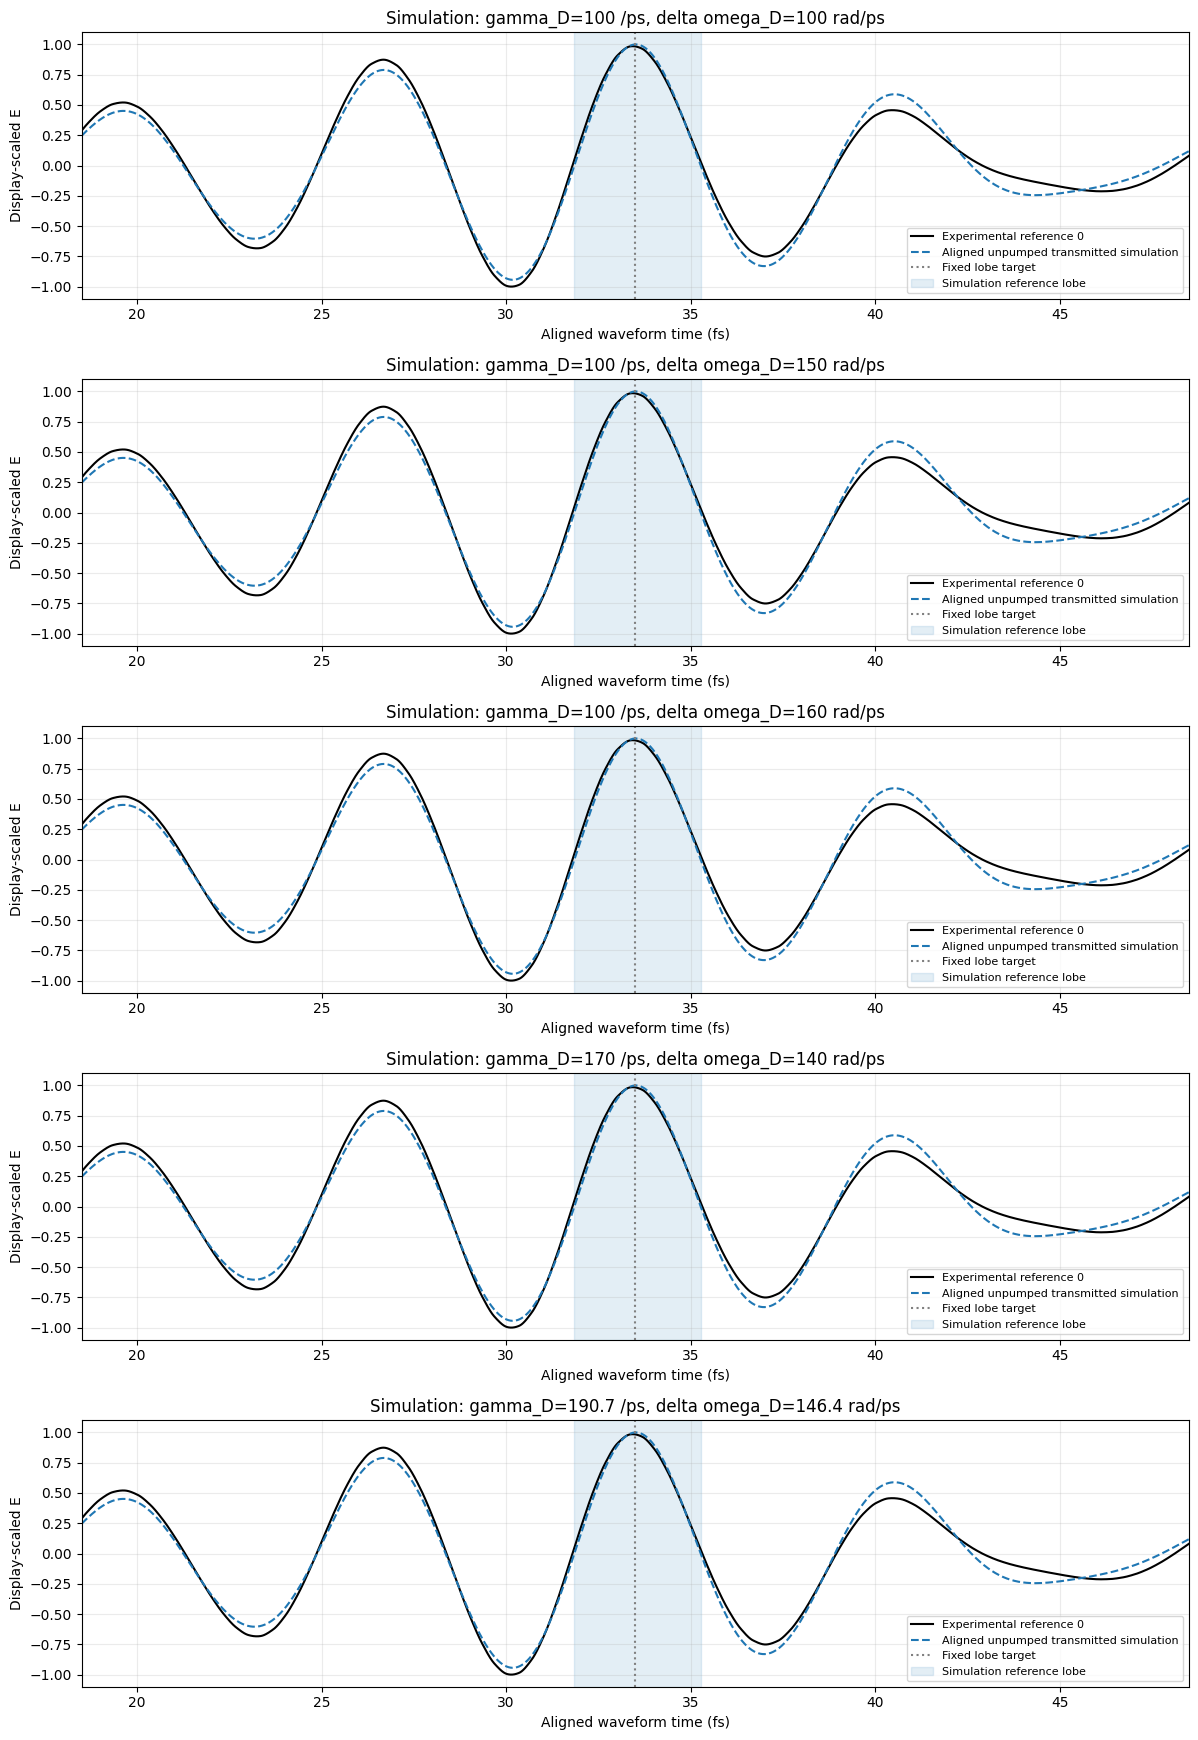

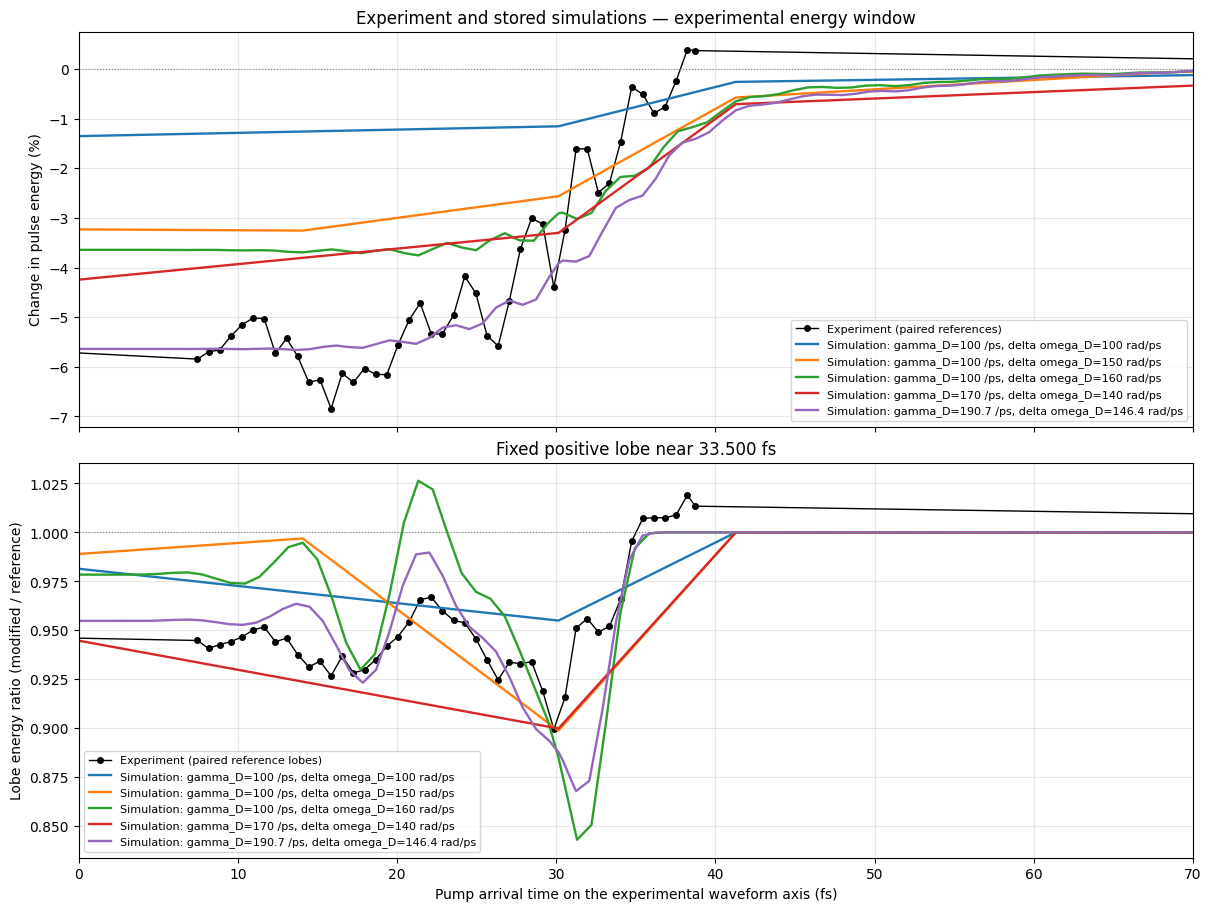

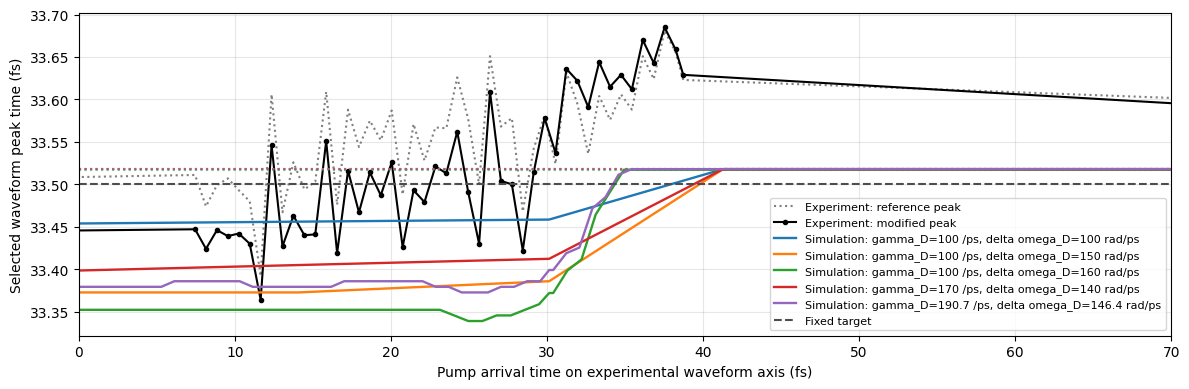

In [17]:
# Alignment preview: display scaling only, never used in energy normalization.
fig, axes = plt.subplots(len(simulated_analyses), 1, figsize=(12, 3.5*len(simulated_analyses)), squeeze=False)
for ax, model in zip(axes[:, 0], simulated_analyses):
    column = model["source_reference_column"]
    ax.plot(t_SI*1e15, _display_scaled(ref_waveforms[:, column]), color="black", label=f"Experimental reference {column}")
    ax.plot(model["reference_time_s"]*1e15, _display_scaled(model["reference_field"]),
            color="C0", ls="--", label="Aligned unpumped transmitted simulation")
    ax.axvline(closest_peak_time_SI*1e15, color="0.5", ls=":", label="Fixed lobe target")
    bounds = model["reference_lobe"]
    ax.axvspan(bounds["left_zero_s"]*1e15, bounds["right_zero_s"]*1e15, color="C0", alpha=0.12, label="Simulation reference lobe")
    ax.set(xlim=(closest_peak_time_SI*1e15-PREVIEW_HALF_WIDTH_FS, closest_peak_time_SI*1e15+PREVIEW_HALF_WIDTH_FS),
           xlabel="Aligned waveform time (fs)", ylabel="Display-scaled E", title=model["label"])
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
alignment_figure = fig
plt.show()


def _plot_model_segments(ax, model, key, *, color, linestyle="-", label=None):
    # Manifest-position gaps break curves for explicitly enabled partial scans.
    positions = model["manifest_positions"]
    segments = np.split(np.arange(positions.size), np.flatnonzero(np.diff(positions) != 1)+1)
    for segment_index, indices in enumerate(segments):
        indices = indices[np.argsort(model["injection_time_fs"][indices], kind="stable")]
        ax.plot(model["injection_time_fs"][indices], model[key][indices], color=color,
                linestyle=linestyle, linewidth=1.7, marker="." if model["partial"] else None,
                label=(model["label"] if label is None else label) if segment_index == 0 else None)


order_exp = np.argsort(injection_times_SI, kind="stable")
comparison_figure, comparison_axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True, constrained_layout=True)
comparison_axes[0].plot(injection_times_SI[order_exp]*1e15, integrated["percent_change"][order_exp],
                        color="black", marker="o", ms=4, lw=1, label="Experiment (paired references)")
comparison_axes[1].plot(injection_times_SI[order_exp]*1e15, lobe["ratio"][order_exp],
                        color="black", marker="o", ms=4, lw=1, label="Experiment (paired reference lobes)")
for j, model in enumerate(simulated_analyses):
    color = f"C{j % 10}"
    _plot_model_segments(comparison_axes[0], model, "pulse_change_percent", color=color)
    _plot_model_segments(comparison_axes[1], model, "lobe_ratio", color=color)
comparison_axes[0].axhline(0, color="0.5", ls=":", lw=0.8)
comparison_axes[1].axhline(1, color="0.5", ls=":", lw=0.8)
comparison_axes[0].set(ylabel="Change in pulse energy (%)", title=f"Experiment and stored simulations — {SIMULATION_ENERGY_WINDOW} energy window")
comparison_axes[1].set(xlabel="Pump arrival time on the experimental waveform axis (fs)",
                       ylabel="Lobe energy ratio (modified / reference)",
                       title=f"Fixed {PEAK_TYPE} lobe near {closest_peak_time_SI*1e15:.3f} fs")
for ax in comparison_axes:
    if COMPARISON_XLIM_FS is not None:
        ax.set_xlim(COMPARISON_XLIM_FS)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
plt.show()

lobe_timing_figure, ax = plt.subplots(figsize=(12, 4))
ax.plot(injection_times_SI[order_exp]*1e15, lobe["reference_peak_time_s"][order_exp]*1e15,
        color="0.5", ls=":", label="Experiment: reference peak")
ax.plot(injection_times_SI[order_exp]*1e15, lobe["modified_peak_time_s"][order_exp]*1e15,
        color="black", marker="o", ms=3, label="Experiment: modified peak")
for j, model in enumerate(simulated_analyses):
    display_model = dict(model, modified_peak_time_fs=model["modified_peak_time_s"]*1e15)
    _plot_model_segments(ax, display_model, "modified_peak_time_fs", color=f"C{j % 10}")
    ax.axhline(model["reference_lobe"]["peak_time_s"]*1e15, color=f"C{j % 10}", ls=":", alpha=0.6)
ax.axhline(closest_peak_time_SI*1e15, color="0.3", ls="--", label="Fixed target")
ax.set(xlabel="Pump arrival time on experimental waveform axis (fs)", ylabel="Selected waveform peak time (fs)")
if COMPARISON_XLIM_FS is not None:
    ax.set_xlim(COMPARISON_XLIM_FS)
ax.grid(alpha=0.3)
ax.legend(fontsize=8)
lobe_timing_figure.tight_layout()
plt.show()

## 11. Save the comparison and its timing choices

Exports retain the exact simulation delay, converted experimental pump-arrival coordinate, selected lobe boundaries, validity flags, and both windowed/full-record pulse ratios. `comparison_metadata.json` records the source datasets, excluded partial scans, waveform translations, injection conversion, integration windows, and selection settings. These are analysis outputs; the stored simulations are left untouched.

In [ ]:
if SAVE_COMPARISON:
    COMPARISON_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    alignment_figure.savefig(COMPARISON_OUTPUT_DIR / "reference_alignment.png", dpi=180)
    comparison_figure.savefig(COMPARISON_OUTPUT_DIR / "experimental_simulated_energy_overplots.png", dpi=180)
    lobe_timing_figure.savefig(COMPARISON_OUTPUT_DIR / "experimental_simulated_lobe_timing.png", dpi=180)
    np.savetxt(COMPARISON_OUTPUT_DIR / "experimental_energy_analysis.csv", results_table,
               delimiter=",", header=results_header, comments="")
    metadata = {
        "experimental_data_directory": str(EXPERIMENTAL_DATA_DIR),
        "waveform_time_unit": TIME_UNIT, "injection_time_unit": inj_unit,
        "waveform_time_shift_fs": WAVEFORM_TIME_SHIFT_FS,
        "injection_time_sign": INJECTION_TIME_SIGN, "injection_time_shift_fs": INJECTION_TIME_SHIFT_FS,
        "simulation_injection_offset_fs": SIMULATION_INJECTION_OFFSET_FS,
        "simulation_injection_mapping": "sign*(validated incident probe peak on its original source time axis in fs - saved delay_fs) + injection shift + simulation offset",
        "waveform_alignment": "one unpumped-reference positive-correlation translation per dataset, or explicit manual override; no modified-trace realignment",
        "energy_window": SIMULATION_ENERGY_WINDOW, "experimental_record_window_fs": [float(t_SI[0]*1e15), float(t_SI[-1]*1e15)],
        "pulse_energy_method": "sum(E**2)*dt on each native uniform grid",
        "peak_type": PEAK_TYPE, "fixed_target_time_fs": closest_peak_time_SI*1e15,
        "peak_prominence_fraction": PEAK_PROMINENCE_FRACTION, "max_peak_distance_fs": MAX_PEAK_DISTANCE_FS,
        "on_lobe_error": ON_LOBE_ERROR, "skipped_scans": skipped_simulation_scans, "datasets": [],
    }
    for model in simulated_analyses:
        filename = model["name"] + "_energy_analysis.npz"
        export_keys = ("manifest_indices", "delay_fs", "injection_time_fs", "pulse_ratio", "pulse_change_percent",
                       "pulse_energy_reference", "pulse_energy_modified", "full_record_pulse_ratio", "lobe_ratio",
                       "lobe_change_percent", "lobe_energy_reference", "lobe_energy_modified", "lobe_valid",
                       "reference_peak_time_s", "modified_peak_time_s", "reference_left_zero_s", "reference_right_zero_s",
                       "modified_left_zero_s", "modified_right_zero_s", "tail_fraction")
        np.savez_compressed(COMPARISON_OUTPUT_DIR / filename,
                            **{key: model[key] for key in export_keys}, lobe_errors=np.asarray(model["lobe_errors"]))
        metadata["datasets"].append({key: model[key] for key in (
            "name", "folder", "label", "partial", "run_folders", "waveform_shift_fs", "automatic_waveform_shift_fs",
            "alignment_score", "source_reference_column", "source_incident_peak_raw_fs", "comparison_window_s",
            "pump_field_exponent", "pump_common_envelope_phase_rad", "pump_common_envelope_phase_label",
        )})
        metadata["datasets"][-1]["analysis_file"] = filename
    (COMPARISON_OUTPUT_DIR / "comparison_metadata.json").write_text(json.dumps(metadata, indent=2))
    print(f"Saved comparison plots, numerical analyses, and alignment metadata to {COMPARISON_OUTPUT_DIR}")